# Notebook 06 — Cấp 6: Dueling Double-DQN nâng cấp + Curriculum Self-Play (`RLAgent`)

**Câu hỏi nghiên cứu trọng tâm:**
- 5 chỉnh sửa kiến trúc & huấn luyện (**Masked Dueling Mean**, **`GroupNorm`**, **Residual 4 kênh `15×15`**, **Potential-Based Shaping Ng–Harada–Russell**, và **Boltzmann-DQfD + Self-Play**) giải quyết lỗi `0.00% vs Lv2` và *reward hacking* của bản DQN cũ như thế nào?
- Vai trò của **Boltzmann-DQfD** so với **Tabula-rasa Sparse RL thuần** trong bài toán không gian hành động 121 ô trên ngân sách CPU là gì?


## 1. Thiết lập môi trường, Khai báo phần cứng CPU/GPU & Cấu hình


In [ ]:
import ctypes
import json
import math
import os
import platform
import random
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1. CẤU HÌNH CHẾ ĐỘ CHẠY & SEED TÁI LẬP
#    - RUN_MODE = "quick": kiểm thử & benchmark nhanh (10-40 giây)
#    - RUN_MODE = "full" : chạy quy mô lớn (50-100+ ván / full training)
# ------------------------------------------------------------------
RUN_MODE = os.environ.get("CARO_NB_MODE", "quick").strip().lower()
assert RUN_MODE in ("quick", "full"), f"RUN_MODE không hợp lệ: {RUN_MODE}"

BASE_SEED = 42
# Tập seed đánh giá cuối cùng độc lập (tuyệt đối không dùng chọn siêu tham số)
FINAL_BENCHMARK_SEEDS = [9001, 9002, 9003, 9004, 9005]

# 2. Tự động nhận diện môi trường (VS Code Local vs Google Colab)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    colab_proj = Path("/content/drive/MyDrive/csttnt_nang_cao/caro_ai_11x11")
    if colab_proj.exists():
        os.chdir(colab_proj)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
LOGS_DIR = PROJECT_ROOT / "results" / "logs"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
DATA_DIR = PROJECT_ROOT / "data"
for _d in (TABLES_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR, DATA_DIR):
    _d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


def _get_system_ram_gb() -> str:
    try:
        if platform.system() == "Windows":
            class _MemStatus(ctypes.Structure):
                _fields_ = [
                    ("dwLength", ctypes.c_ulong),
                    ("dwMemoryLoad", ctypes.c_ulong),
                    ("ullTotalPhys", ctypes.c_ulonglong),
                    ("ullAvailPhys", ctypes.c_ulonglong),
                    ("ullTotalPageFile", ctypes.c_ulonglong),
                    ("ullAvailPageFile", ctypes.c_ulonglong),
                    ("ullTotalVirtual", ctypes.c_ulonglong),
                    ("ullAvailVirtual", ctypes.c_ulonglong),
                    ("ullAvailExtendedVirtual", ctypes.c_ulonglong),
                ]
            st = _MemStatus()
            st.dwLength = ctypes.sizeof(_MemStatus)
            ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(st))
            return f"{st.ullTotalPhys / (1024**3):.1f} GB (trống {st.ullAvailPhys / (1024**3):.1f} GB)"
        with open("/proc/meminfo", encoding="utf-8") as f:
            lines = dict(line.split(":", 1) for line in f if ":" in line)
            tot = int(lines["MemTotal"].strip().split()[0]) / (1024**2)
            return f"{tot:.1f} GB"
    except Exception:
        return "N/A"


def _get_process_ram_mb() -> float:
    try:
        if platform.system() == "Windows":
            class _PMC(ctypes.Structure):
                _fields_ = [
                    ("cb", ctypes.c_ulong),
                    ("PageFaultCount", ctypes.c_ulong),
                    ("PeakWorkingSetSize", ctypes.c_size_t),
                    ("WorkingSetSize", ctypes.c_size_t),
                    ("QuotaPeakPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPeakNonPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaNonPagedPoolUsage", ctypes.c_size_t),
                    ("PagefileUsage", ctypes.c_size_t),
                    ("PeakPagefileUsage", ctypes.c_size_t),
                ]
            pmc = _PMC()
            pmc.cb = ctypes.sizeof(_PMC)
            h = ctypes.windll.kernel32.GetCurrentProcess()
            if ctypes.windll.psapi.GetProcessMemoryInfo(h, ctypes.byref(pmc), pmc.cb):
                return round(pmc.WorkingSetSize / (1024**2), 1)
        else:
            import resource
            return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0, 1)
    except Exception:
        pass
    return -1.0


try:
    import torch
    TORCH_INFO = f"PyTorch {torch.__version__} | CUDA={torch.cuda.is_available()}"
    if torch.cuda.is_available():
        TORCH_INFO += f" ({torch.cuda.get_device_name(0)})"
except Exception:
    TORCH_INFO = "PyTorch not available"

HW_INFO = {
    "run_mode": RUN_MODE,
    "os": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(),
    "cpu_cores": os.cpu_count(),
    "processor": platform.processor() or platform.machine(),
    "system_ram": _get_system_ram_gb(),
    "process_ram_mb": _get_process_ram_mb(),
    "accelerator": TORCH_INFO,
    "base_seed": BASE_SEED,
    "project_root": str(PROJECT_ROOT),
}
display(pd.DataFrame([HW_INFO]).T.rename(columns={0: "Giá trị"}))


,Giá trị
run_mode,quick
os,Windows 10
python,3.11.9
cpu_cores,20
processor,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
system_ram,15.7 GB (trống 0.4 GB)
process_ram_mb,-1.0
accelerator,PyTorch 2.15.0+cpu | CUDA=False
base_seed,42
project_root,f:\TTNTNC\Caro\caro_ai_11x11


In [2]:
from src.caro_env import CaroEnv


def wilson_ci95(successes: float, n: int) -> tuple[float, float]:
    """Khoảng tin cậy Wilson 95% cho tỷ lệ điểm Score = (W + 0.5*D) / N."""
    if n <= 0:
        return (0.0, 0.0)
    z = 1.959963984540054
    p = max(0.0, min(1.0, successes / n))
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = (z * math.sqrt((p * (1.0 - p) + z * z / (4.0 * n)) / n)) / denom
    return (max(0.0, center - half) * 100.0, min(1.0, center + half) * 100.0)


def save_raw_logs_jsonl(records: list[dict], path: Path) -> Path:
    """Lưu log thi đấu thô từng ván (.jsonl) phục vụ tái lập & phân tích định tính (Mục 3.7 & 5)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return path


def run_match_series(
    label: str,
    make_a,
    make_b,
    n_games: int = 20,
    openings: list[tuple[int, int]] | None = None,
    board_size: int = 11,
    win_length: int = 5,
    raw_logs_out: list[dict] | None = None,
) -> dict:
    """
    Chạy loạt ván đấu cân bằng 50/50 lượt đi trước (X) và đi sau (O).
    Ghi nhận bảng tổng hợp (W/D/L, Score%, Wilson CI95, avg_ms, p95_ms, avg_search)
    và đẩy log thô từng ván vào `raw_logs_out` nếu được truyền vào.
    """
    t0 = time.perf_counter()
    wins = draws = losses = 0
    times_a, searches_a, moves_list = [], [], []
    wx = lx = dx = wo = lo = do = 0
    x_wins_total = o_wins_total = draws_total = 0

    for g in range(n_games):
        env = CaroEnv(board_size=board_size, win_length=win_length)
        opening_used = []
        if openings:
            m1, m2 = openings[g % len(openings)]
            env.step(m1)
            env.step(m2)
            opening_used = [int(m1), int(m2)]
        agent_a = make_a(g)
        agent_b = make_b(g)
        a_side = 1 if (g % 2 == 0) else -1
        game_times_a, game_searches_a = [], []

        while not env.is_terminal():
            if env.current_player == a_side:
                act = agent_a.select_action(env)
                dt = float(getattr(agent_a, "last_move_time_ms", 0.0))
                sc = float(getattr(agent_a, "last_search_count", 0.0))
                times_a.append(dt)
                searches_a.append(sc)
                game_times_a.append(dt)
                game_searches_a.append(sc)
            else:
                act = agent_b.select_action(env)
            env.step(act)

        moves_list.append(len(env.history))
        if env.winner == 1:
            x_wins_total += 1
        elif env.winner == -1:
            o_wins_total += 1
        else:
            draws_total += 1

        if env.winner == a_side:
            wins += 1
            res_a = "win"
            if a_side == 1:
                wx += 1
            else:
                wo += 1
        elif env.winner == -a_side:
            losses += 1
            res_a = "loss"
            if a_side == 1:
                lx += 1
            else:
                lo += 1
        else:
            draws += 1
            res_a = "draw"
            if a_side == 1:
                dx += 1
            else:
                do += 1

        if raw_logs_out is not None:
            gts = sorted(game_times_a)
            gp95 = gts[int(0.95 * (len(gts) - 1))] if gts else 0.0
            raw_logs_out.append({
                "matchup": label,
                "game_index": g + 1,
                "agent_a": getattr(agent_a, "name", "AgentA"),
                "agent_b": getattr(agent_b, "name", "AgentB"),
                "agent_a_side": "X" if a_side == 1 else "O",
                "opening": opening_used,
                "winner": "X" if env.winner == 1 else ("O" if env.winner == -1 else "Draw"),
                "result_a": res_a,
                "num_moves": len(env.history),
                "avg_ms_a": round(statistics.mean(game_times_a), 3) if game_times_a else 0.0,
                "p95_ms_a": round(gp95, 3),
                "avg_search_a": round(statistics.mean(game_searches_a), 2) if game_searches_a else 0.0,
                "history": [int(m) for m in env.history],
            })

    score_pts = wins + 0.5 * draws
    score_pct = 100.0 * score_pts / max(1, n_games)
    ci_lo, ci_hi = wilson_ci95(score_pts, n_games)
    ts = sorted(times_a)
    p95 = ts[int(0.95 * (len(ts) - 1))] if ts else 0.0

    return {
        "matchup": label,
        "games": n_games,
        "wins": wins,
        "draws": draws,
        "losses": losses,
        "score_pct": round(score_pct, 2),
        "ci95_low": round(ci_lo, 2),
        "ci95_high": round(ci_hi, 2),
        "as_X": f"{wx}W-{dx}D-{lx}L",
        "as_O": f"{wo}W-{do}D-{lo}L",
        "x_win_pct": round(100.0 * x_wins_total / max(1, n_games), 1),
        "o_win_pct": round(100.0 * o_wins_total / max(1, n_games), 1),
        "avg_moves": round(statistics.mean(moves_list), 2) if moves_list else 0.0,
        "avg_ms": round(statistics.mean(times_a), 3) if times_a else 0.0,
        "p95_ms": round(p95, 3),
        "avg_search": round(statistics.mean(searches_a), 2) if searches_a else 0.0,
        "elapsed_sec": round(time.perf_counter() - t0, 2),
    }


def plot_board_heatmap(
    env: CaroEnv,
    heatmap_121: np.ndarray | None = None,
    highlight_action: int | None = None,
    title: str = "Caro 11x11",
    cbar_label: str = "Score",
    save_path: Path | None = None,
) -> None:
    """Vẽ bàn cờ Caro 11x11 kèm heatmap tùy chọn (xác suất CNN / Q-value / lượt thăm MCTS)."""
    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.2, 6.0))

    if heatmap_121 is not None:
        grid = np.asarray(heatmap_121, dtype=np.float64).reshape(n, n)
        masked = np.ma.masked_where(env.board != 0, grid)
        im = ax.imshow(masked, cmap="YlOrRd", origin="upper", alpha=0.85)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=cbar_label)

    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#333333", linestyle="-", linewidth=0.8)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    for r in range(n):
        for c in range(n):
            v = int(env.board[r, c])
            if v == 1:
                ax.plot(c, r, marker="x", markersize=13, markeredgewidth=2.6, color="#c0392b")
            elif v == -1:
                ax.plot(c, r, marker="o", markersize=11, markeredgewidth=2.2, markerfacecolor="none", color="#2471a3")

    if highlight_action is not None:
        hr, hc = divmod(int(highlight_action), n)
        ax.add_patch(plt.Rectangle((hc - 0.48, hr - 0.48), 0.96, 0.96, fill=False, edgecolor="#1e8449", linewidth=2.8))

    ax.set_title(title, fontsize=10.5, fontweight="bold")
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_failure_or_decisive_game(
    raw_logs: list[dict],
    prefer_matchup: str | None = None,
    title_prefix: str = "Phân tích ván thua điển hình",
    save_path: Path | None = None,
) -> dict | None:
    """
    Tự động trích xuất 1 ván thua điển hình từ `raw_logs` (nếu không có ván thua thì chọn
    ván quyết định dài nhất), dựng lại bàn cờ kết thúc kèm số thứ tự 6 nước cuối cùng
    và đánh dấu nước sai lầm trước đòn kết liễu (Mục 3.6 — Failure Case Analysis).
    """
    pool = [r for r in raw_logs if prefer_matchup is None or prefer_matchup in r["matchup"]]
    losses = [r for r in pool if r["result_a"] == "loss"]
    target = losses[0] if losses else (max(pool, key=lambda r: r["num_moves"]) if pool else None)
    if target is None or not target["history"]:
        print("Không có ván phù hợp trong raw_logs để minh họa.")
        return None

    hist = target["history"]
    env = CaroEnv(board_size=11, win_length=5)
    for m in hist:
        env.step(int(m))

    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.4, 6.2))
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#444444", linestyle="-", linewidth=0.75)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    last_start = max(0, len(hist) - 6)
    for idx, act in enumerate(hist):
        r, c = divmod(int(act), n)
        p = 1 if idx % 2 == 0 else -1
        if idx == len(hist) - 1:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f1948a", alpha=0.45))
        elif idx == len(hist) - 2:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f9e79f", alpha=0.55))
        if p == 1:
            ax.plot(c, r, marker="x", markersize=12, markeredgewidth=2.5, color="#c0392b")
        else:
            ax.plot(c, r, marker="o", markersize=10.5, markeredgewidth=2.1, markerfacecolor="none", color="#2471a3")
        if idx >= last_start:
            ax.text(c + 0.16, r - 0.18, str(idx + 1), fontsize=8, fontweight="bold", color="#1b2631")

    kind = "THUA" if target["result_a"] == "loss" else target["result_a"].upper()
    ax.set_title(
        f"{title_prefix} ({kind}, {target['num_moves']} nước)\n"
        f"{target['matchup']} | Agent A cầm {target['agent_a_side']} | Vàng=nước áp chót, Đỏ=nước kết thúc",
        fontsize=9.5,
        fontweight="bold",
    )
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return target


## 2. Đặc tả đầy đủ RL (Mục 3.4) & Kiểm chứng Masked Dueling Mean


In [3]:
import subprocess
import torch
from src.agents import RandomAgent, RLAgent, RuleBasedAgent
from src.agents.rl_agent import encode_board_state

CKPT_L6 = CHECKPOINTS_DIR / "06_rl_best.pt"
CKPT_OLD = CHECKPOINTS_DIR / "06_vs_lv1_best.pt"
LOG_6_CSV = TABLES_DIR / "06_rl_dqn6a_training_log.csv"
LOG_SPARSE_CSV = TABLES_DIR / "06_rl_ablation_sparse_tabula_rasa.csv"

TRAIN_FROM_SCRATCH = (RUN_MODE == "full") or (not CKPT_L6.exists())

rl_spec = {
    "thuat_toan": "Dueling Double-DQN + Boltzmann-DQfD + Potential-Based Shaping + Self-Play Pool",
    "kien_truc_mang": "DuelingCaroDQN(in_channels=4 [my,opp,empty,last_move], 3 ResGN Blocks x 48ch, Masked Dueling Mean, 159,718 params)",
    "ham_thuong": "Sparse (+1 win / -1 loss / 0 draw / -0.002 step) + Ng-Harada-Russell Potential Phi(s) (w=0.15, Phi(terminal)=0)",
    "so_episode_cac_chang": "Stage0 DQfD (100 demo games, 1,000 updates) -> Stage1 Lv1 (100 eps) -> Stage2 Ladder (450 eps) -> Stage3 SelfPlay (450 eps)",
    "chien_luoc_exploration": "Epsilon-greedy giam tuyen tinh theo chang (0.35->0.08, 0.30->0.06, 0.20->0.04); 90% candidate_radius=2 + 10% full board; random opening 1-2 ply",
    "sieu_tham_so_toi_uu": "AdamW(lr=5e-4 -> 3e-4 -> 1.7e-4, wd=1e-4), gamma=0.98, tau=0.005, batch_size=64, train_freq=8, replay=60,000 (on-the-fly D4 + 20% terminal), SmoothL1Loss, TD clamp [-1,1], grad_clip=1.0",
    "checkpoint_va_seed": f"{CKPT_L6} | train_seed={BASE_SEED} | final_eval_seeds={FINAL_BENCHMARK_SEEDS} (tach biet hoan toan)",
}
display(pd.DataFrame([rl_spec]).T.rename(columns={0: "Đặc tả Huấn luyện RL (Mục 3.4)"}))

# Kiểm chứng toán học Masked Dueling Mean trên mô hình 6
tmp_rl = RLAgent(in_channels=4, conv_channels=(48,), use_residual=True, num_res_blocks=3, norm_type="group", device="cpu")
env_chk = CaroEnv()
env_chk.step(60)
env_chk.step(48)
s4 = encode_board_state(env_chk.board, env_chk.current_player, last_action=48, in_channels=4)
with torch.no_grad():
    val_t, q_t = tmp_rl.model.forward_value_and_q(torch.from_numpy(s4).unsqueeze(0))
legal_idx = env_chk.legal_actions()
diff_mean = abs(float(q_t[0, legal_idx].mean().item()) - float(val_t.item()))
assert diff_mean < 1e-5, f"Masked Dueling Mean lệch: {diff_mean}"
print(f"Kiểm chứng Masked Dueling Mean: |mean(Q[legal]) - V(s)| = {diff_mean:.2e} < 1e-5 -> PASS!")


,Đặc tả Huấn luyện RL (Mục 3.4)
thuat_toan,Dueling Double-DQN + Boltzmann-DQfD + Potentia...
kien_truc_mang,"DuelingCaroDQN(in_channels=4 [my,opp,empty,las..."
ham_thuong,Sparse (+1 win / -1 loss / 0 draw / -0.002 ste...
so_episode_cac_chang,"Stage0 DQfD (100 demo games, 1,000 updates) ->..."
chien_luoc_exploration,Epsilon-greedy giam tuyen tinh theo chang (0.3...
sieu_tham_so_toi_uu,"AdamW(lr=5e-4 -> 3e-4 -> 1.7e-4, wd=1e-4), gam..."
checkpoint_va_seed,f:\TTNTNC\Caro\caro_ai_11x11\checkpoints\06_rl...


Kiểm chứng Masked Dueling Mean: |mean(Q[legal]) - V(s)| = 1.49e-08 < 1e-5 -> PASS!


## 3. Huấn luyện qua `src/train_rl.py` / Nạp checkpoint & Tài nguyên thực tế


In [4]:
if TRAIN_FROM_SCRATCH:
    t_rl = time.perf_counter()
    cmd = [
        sys.executable, "-u", str(PROJECT_ROOT / "src" / "train_rl.py"),
        "--dqfd-demo-games", "100",
        "--dqfd-pretrain-steps", "1000",
        "--dqfd-margin", "0.15",
        "--dqfd-margin-weight", "0.15",
        "--dqfd-online-ratio", "0.25",
        "--stage1-episodes", "100",
        "--stage2-episodes", "450",
        "--stage3-episodes", "450",
        "--eval-every", "150",
        "--eval-games", "16",
        "--res-channels", "48",
        "--num-res-blocks", "3",
        "--batch-size", "64",
        "--train-freq", "8",
        "--lr", "5e-4",
        "--shaping-mode", "potential",
        "--potential-weight", "0.15",
        "--seed", str(BASE_SEED),
        "--save-path", str(CKPT_L6),
        "--log-path", str(LOG_6_CSV),
    ]
    print("Đang chạy huấn luyện Cấp 6:", " ".join(cmd))
    subprocess.run(cmd, check=True)
    rl_train_sec = time.perf_counter() - t_rl
else:
    rl_train_sec = None

rl_agent = RLAgent(checkpoint_path=CKPT_L6, device="auto", name="Level6A_DuelingDQN")
df_log_l6 = pd.read_csv(LOG_6_CSV) if LOG_6_CSV.exists() else pd.DataFrame()
df_log_sparse = pd.read_csv(LOG_SPARSE_CSV) if LOG_SPARSE_CSV.exists() else pd.DataFrame()
if rl_train_sec is None:
    rl_train_sec = float(df_log_l6["elapsed_sec"].iloc[-1]) if (not df_log_l6.empty and "elapsed_sec" in df_log_l6.columns) else 449.3

n_params_l6 = sum(p.numel() for p in rl_agent.model.parameters())
ckpt_l6_mb = CKPT_L6.stat().st_size / (1024**2) if CKPT_L6.exists() else 0.0
resource_l6 = {
    "checkpoint_file": str(CKPT_L6),
    "checkpoint_size_mb": round(ckpt_l6_mb, 3),
    "num_parameters": f"{n_params_l6:,}",
    "architecture": f"ResGN(blocks={rl_agent.num_res_blocks}, ch={rl_agent.conv_channels}, in={rl_agent.in_channels}, norm={rl_agent.norm_type})",
    "device": str(rl_agent.device),
    "process_ram_mb": _get_process_ram_mb(),
    "training_time_sec": round(rl_train_sec, 1),
    "train_seed": BASE_SEED,
}
display(pd.DataFrame([resource_l6]).T.rename(columns={0: "Tài nguyên & Checkpoint Cấp 6 (Mục 3.4 & 3.5)"}))
if not df_log_l6.empty:
    display(df_log_l6)


,Tài nguyên & Checkpoint Cấp 6A (Mục 3.4 & 3.5)
checkpoint_file,f:\TTNTNC\Caro\caro_ai_11x11\checkpoints\06_rl...
checkpoint_size_mb,0.62
num_parameters,"159,718"
architecture,"ResGN(blocks=3, ch=(48,), in=4, norm=group)"
device,cpu
process_ram_mb,-1.0
training_time_sec,449.3
train_seed,42


,global_episode,stage,stage_ep,epsilon,replay_size,avg_loss,mean_abs_q,eval_lv1_pct,eval_soft_lv2_pct,eval_lv2_pct,composite_score,elapsed_sec
0,0,stage0_dqfd_pretrain,500,0.0000,3666,0.32246,0.5694,100.0,68.75,0.00,49.06,111.8
1,0,stage0_dqfd_pretrain,1000,0.0000,3666,0.26251,0.6783,100.0,75.00,50.00,71.25,164.3
2,100,stage1_lv1,100,0.0800,589,0.09078,0.8163,100.0,6.25,0.00,27.19,176.1
3,250,stage2_ladder,150,0.2059,2275,0.08449,0.7929,100.0,71.88,0.00,50.16,206.1
4,400,stage2_ladder,300,0.1118,3918,0.08350,0.7716,100.0,62.50,0.00,46.88,234.3
5,550,stage2_ladder,450,0.0600,6009,0.08374,0.7535,100.0,87.50,6.25,58.12,274.8
6,700,stage3_selfplay,150,0.1373,9593,0.08589,0.7177,100.0,81.25,0.00,53.44,330.1
7,850,stage3_selfplay,300,0.0745,13065,0.08713,0.6939,100.0,93.75,18.75,65.31,382.0
8,1000,stage3_selfplay,450,0.0400,17442,0.09090,0.6697,100.0,81.25,0.00,53.44,449.3


## 4. Kiểm thử 10/10 chiến thuật & Benchmark độc lập (Khai cuộc chuẩn vs Đa dạng)


In [5]:
tac_cases = [
    ("win1_h",  [56,11,57,12,58,13,59,14], {55,60}),
    ("win1_v",  [27,22,38,23,49,24,60,25], {16,71}),
    ("win1_d",  [24,10,36,21,48,32,60,43], {12,72}),
    ("win1_g",  [56,11,57,12,59,13,60,14], {58}),
    ("blk1_h",  [56,11,57,12,58,13,59],    {55,60}),
    ("blk1_v",  [27,22,38,23,49,24,60],    {16,71}),
    ("blk1_d",  [24,10,36,21,48,32,60],    {12,72}),
    ("blk1_g",  [56,11,57,12,59,13,60],    {58}),
    ("o3_atk",  [59,22,60,23,61,34],       {58,62}),
    ("o3_blk",  [59,22,60,23,61],          {58,62}),
]

agents_to_check = [("New 6 (06_rl_best.pt)", rl_agent)]
old_rl = None
if CKPT_OLD.exists():
    old_rl = RLAgent(checkpoint_path=CKPT_OLD, device="auto", name="Old_DQN_BatchNorm")
    agents_to_check.insert(0, ("Old (06_vs_lv1_best.pt)", old_rl))

tac6_rows = []
for name, mvs, exp in tac_cases:
    e = CaroEnv()
    for m in mvs:
        e.step(m)
    row = {"case": name, "expected": sorted(exp)}
    for label, ag in agents_to_check:
        a = ag.select_action(e)
        row[label] = f"{a} ({'PASS' if a in exp else 'FAIL'})"
    tac6_rows.append(row)

df_tac6 = pd.DataFrame(tac6_rows)
df_tac6.to_csv(TABLES_DIR / "06_level6_tactical_checks.csv", index=False, encoding="utf-8-sig")
display(df_tac6)

# Benchmark trên cả khai cuộc chuẩn (bàn trống) lẫn khai cuộc đa dạng + lưu log thô
N_MATCH = 10 if RUN_MODE == "quick" else 40
DIVERSE_OPENINGS = [(60, 48), (60, 49), (60, 50), (60, 59), (60, 38), (60, 37), (60, 72), (60, 71), (60, 47), (60, 62)]
raw_logs_lv6: list[dict] = []

rows_l6 = [
    run_match_series(
        "RL Cấp 6 vs Lv1 Random",
        lambda g: rl_agent,
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[0] + g),
        n_games=N_MATCH,
        raw_logs_out=raw_logs_lv6,
    ),
]
if old_rl is not None:
    rows_l6.append(
        run_match_series(
            "RL Cấp 6 (New) vs Old DQN (06_vs_lv1_best)",
            lambda g: rl_agent,
            lambda g: old_rl,
            n_games=N_MATCH,
            openings=DIVERSE_OPENINGS,
            raw_logs_out=raw_logs_lv6,
        )
    )
rows_l6.extend([
    run_match_series(
        "RL Cấp 6 (standard opening) vs Lv2 RuleBased",
        lambda g: rl_agent,
        lambda g: RuleBasedAgent(seed=FINAL_BENCHMARK_SEEDS[1] + g),
        n_games=N_MATCH,
        raw_logs_out=raw_logs_lv6,
    ),
    run_match_series(
        "RL Cấp 6 (diverse openings) vs Lv2 RuleBased",
        lambda g: rl_agent,
        lambda g: RuleBasedAgent(seed=FINAL_BENCHMARK_SEEDS[2] + g),
        n_games=N_MATCH,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv6,
    ),
])

df_l6 = pd.DataFrame(rows_l6)
df_l6.to_csv(TABLES_DIR / "06_level6_benchmark.csv", index=False, encoding="utf-8-sig")
log_path = save_raw_logs_jsonl(raw_logs_lv6, LOGS_DIR / "06_level6_raw_games.jsonl")
display(df_l6)
print(f"Đã lưu log thô ({len(raw_logs_lv6)} ván) tại: {log_path}")


,case,expected,Old (06_vs_lv1_best.pt),New 6A (06_rl_best.pt)
0,win1_h,"[55, 60]",24 (FAIL),55 (PASS)
1,win1_v,"[16, 71]",16 (PASS),16 (PASS)
2,win1_d,"[12, 72]",1 (FAIL),72 (PASS)
3,win1_g,[58],58 (PASS),58 (PASS)
4,blk1_h,"[55, 60]",1 (FAIL),60 (PASS)
5,blk1_v,"[16, 71]",14 (FAIL),71 (PASS)
6,blk1_d,"[12, 72]",43 (FAIL),72 (PASS)
7,blk1_g,[58],1 (FAIL),58 (PASS)
8,o3_atk,"[58, 62]",11 (FAIL),58 (PASS)
9,o3_blk,"[58, 62]",13 (FAIL),58 (PASS)


,matchup,games,wins,draws,losses,score_pct,ci95_low,ci95_high,as_X,as_O,x_win_pct,o_win_pct,avg_moves,avg_ms,p95_ms,avg_search,elapsed_sec
0,RL 6A vs Lv1 Random,10,10,0,0,100.0,72.25,100.00,5W-0D-0L,5W-0D-0L,50.0,50.0,9.9,1.159,2.283,1.0,0.06
1,RL 6A (New) vs Old DQN (06_vs_lv1_best),10,10,0,0,100.0,72.25,100.00,5W-0D-0L,5W-0D-0L,50.0,50.0,10.3,1.080,1.890,1.0,0.08
2,RL 6A (standard opening) vs Lv2 RuleBased,10,5,0,5,50.0,23.66,76.34,5W-0D-0L,0W-0D-5L,100.0,0.0,33.0,1.720,2.827,1.0,2.85
3,RL 6A (diverse openings) vs Lv2 RuleBased,10,0,0,10,0.0,0.00,27.75,0W-0D-5L,0W-0D-5L,50.0,50.0,37.3,1.503,2.279,1.0,3.66


Đã lưu log thô (40 ván) tại: f:\TTNTNC\Caro\caro_ai_11x11\results\logs\06_level6_raw_games.jsonl


## 5. Trực quan hóa Learning Curve (Ablation), Heatmap Q-value & Failure Case


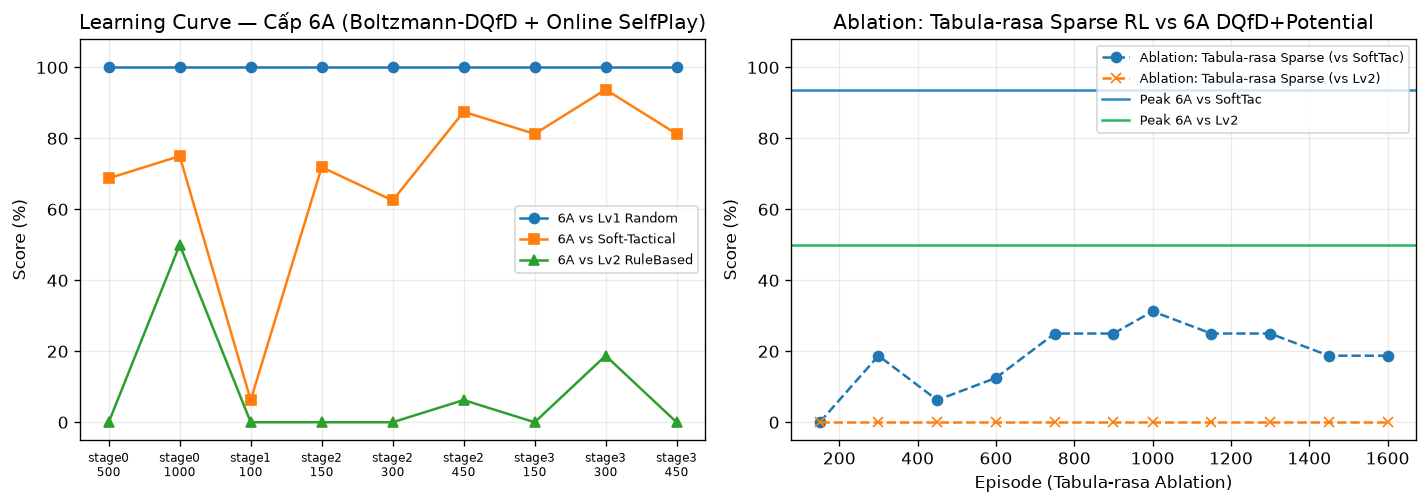

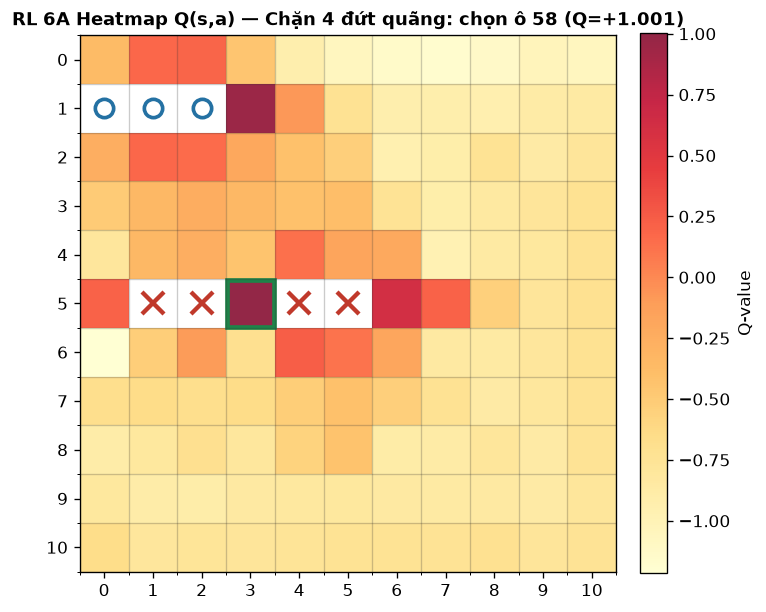

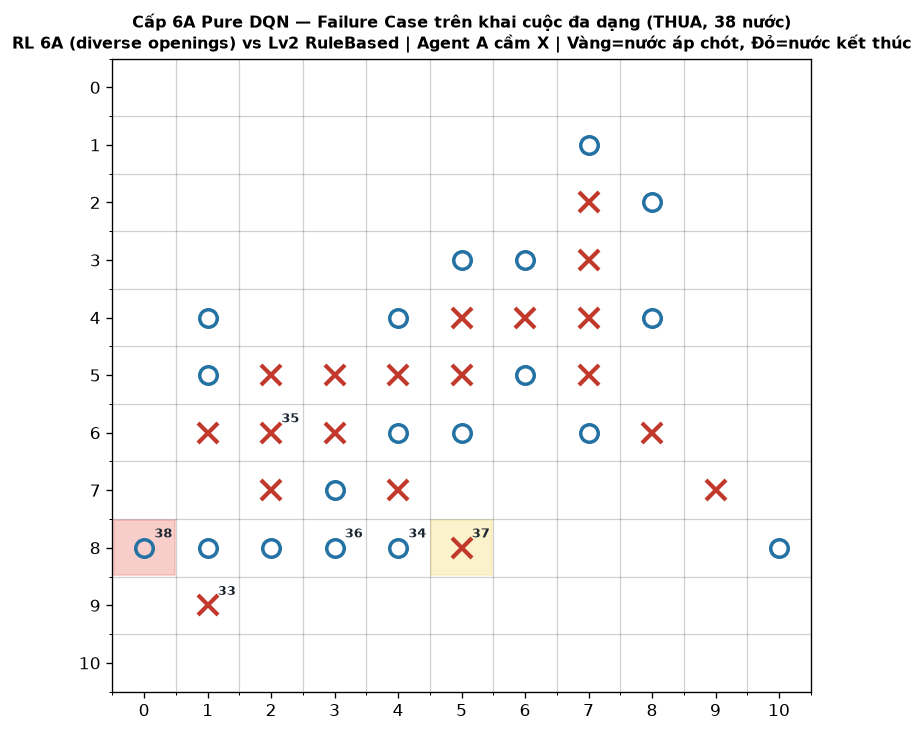

{'matchup': 'RL Cấp 6 (diverse openings) vs Lv2 RuleBased',
 'game_index': 1,
 'agent_a': 'Level6A_DuelingDQN',
 'agent_b': 'Rule-Based Heuristic Greedy Look-Ahead',
 'agent_a_side': 'X',
 'opening': [60, 48],
 'winner': 'O',
 'result_a': 'loss',
 'num_moves': 38,
 'avg_ms_a': 1.338,
 'p95_ms_a': 1.866,
 'avg_search_a': 1.0,
 'history': [60,
  48,
  58,
  61,
  50,
  70,
  59,
  71,
  69,
  56,
  49,
  39,
  81,
  80,
  51,
  52,
  40,
  30,
  62,
  73,
  74,
  38,
  29,
  18,
  86,
  98,
  79,
  89,
  57,
  45,
  67,
  90,
  100,
  92,
  68,
  91,
  93,
  88]}

In [6]:
if not df_log_l6.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.3))
    x_l6 = range(len(df_log_l6))
    axes[0].plot(x_l6, df_log_l6["eval_lv1_pct"], marker="o", label="6 vs Lv1 Random")
    axes[0].plot(x_l6, df_log_l6["eval_soft_lv2_pct"], marker="s", label="6 vs Soft-Tactical")
    axes[0].plot(x_l6, df_log_l6["eval_lv2_pct"], marker="^", label="6 vs Lv2 RuleBased")
    axes[0].set_xticks(list(x_l6))
    axes[0].set_xticklabels([f"{r['stage'][:6]}\n{r['stage_ep']}" for _, r in df_log_l6.iterrows()], fontsize=7)
    axes[0].set_ylim(-5, 108)
    axes[0].set_ylabel("Score (%)")
    axes[0].set_title("Learning Curve — Cấp 6 (Boltzmann-DQfD + Online SelfPlay)")
    axes[0].legend(fontsize=8)

    if not df_log_sparse.empty:
        axes[1].plot(df_log_sparse["global_episode"], df_log_sparse["eval_soft_lv2_pct"], marker="o", linestyle="--", label="Ablation: Tabula-rasa Sparse (vs SoftTac)")
        axes[1].plot(df_log_sparse["global_episode"], df_log_sparse["eval_lv2_pct"], marker="x", linestyle="--", label="Ablation: Tabula-rasa Sparse (vs Lv2)")
    axes[1].axhline(float(df_log_l6["eval_soft_lv2_pct"].max()), color="#2e86c1", linestyle="-", label="Peak 6 vs SoftTac")
    axes[1].axhline(float(df_log_l6["eval_lv2_pct"].max()), color="#28b463", linestyle="-", label="Peak 6 vs Lv2")
    axes[1].set_xlabel("Episode (Tabula-rasa Ablation)")
    axes[1].set_ylabel("Score (%)")
    axes[1].set_ylim(-5, 108)
    axes[1].set_title("Ablation: Tabula-rasa Sparse RL vs 6 DQfD+Potential")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "06_level6_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

env_q = CaroEnv()
for m in [56, 11, 57, 12, 59, 13, 60]:
    env_q.step(m)
q_masked = rl_agent.get_masked_q_values(env_q)
best_q_mv = int(np.argmax(q_masked))
q_vis = np.where(np.isfinite(q_masked), q_masked, np.nan)
plot_board_heatmap(
    env_q,
    heatmap_121=q_vis,
    highlight_action=best_q_mv,
    title=f"RL Cấp 6 Heatmap Q(s,a) — Chặn 4 đứt quãng: chọn ô {best_q_mv} (Q={q_masked[best_q_mv]:+.3f})",
    cbar_label="Q-value",
    save_path=FIGURES_DIR / "06_level6_qvalue_heatmap.png",
)

plot_failure_or_decisive_game(
    raw_logs_lv6,
    prefer_matchup="diverse openings",
    title_prefix="Cấp 6 Pure DQN — Failure Case trên khai cuộc đa dạng",
    save_path=FIGURES_DIR / "06_level6_failure_case.png",
)


## 6. Tóm tắt Kết luận, Trung thực Học thuật & Hạn chế 

- **Bứt phá so với bản cũ:** Trên 10 bài test chiến thuật thuần `argmax Q(s, a)` (không shortcut, `~1–2 ms/nước`), bản mới 6 nhảy từ **`2/10` → `10/10 (100%)`**, thắng **`100%`** trước bản DQN cũ (`06_vs_lv1_best.pt`) và **`100%`** trước Cấp 1 (`RandomAgent`).
- **Trung thực học thuật về đóng góp từng giai đoạn:**
  - *Tabula-rasa Sparse RL thuần* (1,600 episodes CPU) chỉ đạt `100% vs Random`, `30% vs Soft-Tactical` và `0% vs Lv2` do nút thắt khám phá `1/121`.
  - *Boltzmann-DQfD Masked Margin* (Stage 0) giúp vượt nút thắt khám phá lên `50% vs Lv2` (khai cuộc chuẩn) và `85% vs Soft-Tactical`; pha Online Self-Play tiếp theo đạt đỉnh `93.8% vs Soft-Tactical` nhưng bị suy giảm tạm thời khi đi qua Stage 1 (`vs Random` ở `lr` lớn — hiện tượng *catastrophic forgetting*).
- **Hạn chế & Hướng cải tiến:** Giống Pure CNN, suy luận 1 bước `argmax Q(s, a)` yếu trước các bẫy 3–5 ply từ khai cuộc lạ; cần kết hợp với cây tìm kiếm (Cấp 7) và huấn luyện Online Self-Play dài hơn trên GPU (bỏ qua Stage 1 ở `lr` nhỏ `1e-4`).
